Fold acc: [0.8 0.9 0.9 0.8 1.  1.  1.  0.9 1.  1. ] Mean: 0.93
0.95


{'C': 1, 'kernel': 'linear'} 0.99


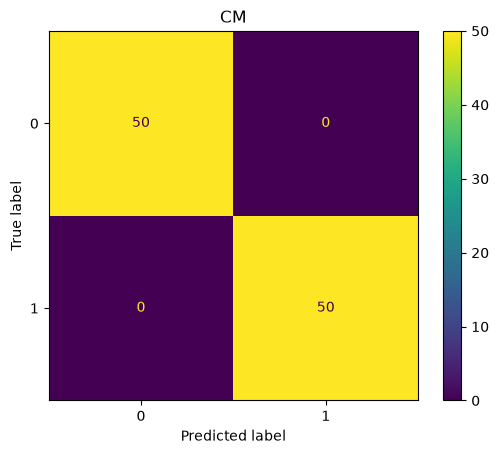

In [1]:
# ===================== REVISION / ONE-SHOT: VALIDATION + TUNING =====================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, load_iris
from sklearn.model_selection import KFold, StratifiedKFold, LeaveOneOut, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import resample
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

X, y = make_classification(n_samples=100, n_features=20, random_state=42)

# 1) K-Fold loop pattern (same for StratifiedKFold / LeaveOneOut, just swap the splitter)
kf = KFold(n_splits=10, shuffle=True, random_state=42)      # StratifiedKFold(5, ...) / LeaveOneOut()
scores = []
for train_idx, test_idx in kf.split(X, y):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    sc = StandardScaler().fit(X_train)                      # fit scaler on train fold only
    model = SVC().fit(sc.transform(X_train), y_train)
    scores.append(accuracy_score(y_test, model.predict(sc.transform(X_test))))
print("Fold acc:", np.round(scores, 3), "Mean:", np.mean(scores))

# 2) One-liner alternative
print(cross_val_score(SVC(), X, y, cv=10).mean())

# 3) Bootstrap: sample rows WITH replacement, same size as data
X_bs, y_bs = resample(X, y, replace=True, random_state=0)

# 4) Grid search
grid = GridSearchCV(SVC(), {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"]}, cv=5)
grid.fit(X, y)
print(grid.best_params_, grid.best_score_)
ConfusionMatrixDisplay.from_estimator(grid.best_estimator_, X, y); plt.title("CM"); plt.show()

# ---------------- VIVA NOTES ----------------
# K-Fold: data split into k parts, each part is test once; final score = mean of k scores.
# Stratified K-Fold keeps class ratio in every fold (use for imbalanced / multi-class data).
# LOOCV = K-Fold with k = n samples; nearly unbiased but slow (n model fits).
# Bootstrap: sample with replacement; ~63.2% unique rows in each sample, rest are out-of-bag.
# GridSearchCV tries every param combination with CV, best_params_ / best_estimator_ give winner.
# Scale inside each fold (or use Pipeline) to avoid data leakage.

### Q21

Write a Python code to perform k-fold cross-validation on the dataset using a Support Vector Machine (SVM) classifier. Use the following steps:

- Import necessary libraries.
- Prepare the dataset synthetically using make_classification.
- Preprocess the data if necessary (e.g., scaling).
- Implement k-fold cross-validation with 10 folds.
- Train the SVM classifier on the training set and evaluate it on the test set for each fold.
- Print the accuracy for each fold and the average accuracy across all folds.

Dataset Description:
- The dataset consists of 100 samples with 20 features.

The target variable is binary (0 or 1).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [3]:
# 100 samples, 20 features, binary target
X, y = make_classification(n_samples=100, n_features=20, n_classes=2, random_state=42)
print("X shape:", X.shape, "| classes:", np.unique(y))

X shape: (100, 20) | classes: [0 1]


In [4]:
# 10-fold cross-validation
kf = KFold(n_splits=10, shuffle=True, random_state=42)
scores = []
for fold, (train_idx, test_idx) in enumerate(kf.split(X), start=1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # scale using train fold only
    sc = StandardScaler()
    X_train = sc.fit_transform(X_train)
    X_test = sc.transform(X_test)

    model = SVC(kernel="rbf", random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    scores.append(acc)
    print(f"Fold {fold}: accuracy = {acc:.2f}")

print("Average accuracy:", round(np.mean(scores), 4))

Fold 1: accuracy = 0.80
Fold 2: accuracy = 0.90
Fold 3: accuracy = 0.90
Fold 4: accuracy = 0.80
Fold 5: accuracy = 1.00
Fold 6: accuracy = 1.00
Fold 7: accuracy = 1.00
Fold 8: accuracy = 0.90
Fold 9: accuracy = 1.00
Fold 10: accuracy = 1.00
Average accuracy: 0.93


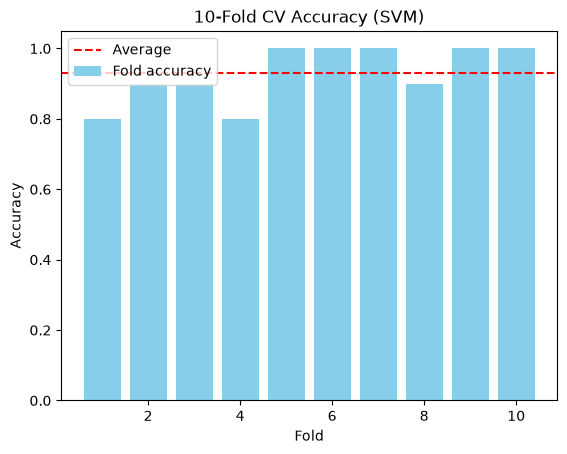

In [5]:
plt.bar(range(1, 11), scores, color="skyblue", label="Fold accuracy")
plt.axhline(np.mean(scores), color="red", linestyle="--", label="Average")
plt.title("10-Fold CV Accuracy (SVM)")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Q22

Write a Python code to perform bootstrap sampling on a dataset using a Random Forest Classifier. The dataset consists of features and labels as specified below.

Dataset Description:
- The dataset consists of 150 samples with 10 features.
- The target variable is categorical with three classes (0, 1, 2).

Instructions:
- Import the necessary libraries.
- Load or create a synthetic dataset with the specified characteristics.
- Implement bootstrap sampling to create multiple samples from the original dataset.
- Train a Random Forest Classifier on each bootstrap sample.
- Evaluate the model on the original dataset and print the accuracy for each bootstrap sample.
- Calculate and print the average accuracy across all bootstrap samples.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import resample
from sklearn.metrics import accuracy_score

In [7]:
# 150 samples, 10 features, 3 classes
X, y = make_classification(n_samples=150, n_features=10, n_informative=5,
                           n_classes=3, random_state=42)
print("X shape:", X.shape, "| classes:", np.unique(y))

X shape: (150, 10) | classes: [0 1 2]


In [8]:
# 10 bootstrap samples (rows drawn with replacement)
n_boot = 10
scores = []
for i in range(n_boot):
    X_bs, y_bs = resample(X, y, replace=True, n_samples=len(X), random_state=i)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_bs, y_bs)
    y_pred = model.predict(X)                      # evaluate on original dataset
    acc = accuracy_score(y, y_pred)
    scores.append(acc)
    print(f"Bootstrap sample {i + 1}: unique rows = {len(np.unique(X_bs, axis=0))}, accuracy = {acc:.4f}")

print("Average accuracy:", round(np.mean(scores), 4))

Bootstrap sample 1: unique rows = 97, accuracy = 0.8933


Bootstrap sample 2: unique rows = 93, accuracy = 0.8933


Bootstrap sample 3: unique rows = 92, accuracy = 0.8733


Bootstrap sample 4: unique rows = 90, accuracy = 0.8200


Bootstrap sample 5: unique rows = 95, accuracy = 0.8867


Bootstrap sample 6: unique rows = 96, accuracy = 0.8667


Bootstrap sample 7: unique rows = 98, accuracy = 0.8800


Bootstrap sample 8: unique rows = 91, accuracy = 0.8533


Bootstrap sample 9: unique rows = 93, accuracy = 0.8600


Bootstrap sample 10: unique rows = 94, accuracy = 0.8467
Average accuracy: 0.8673


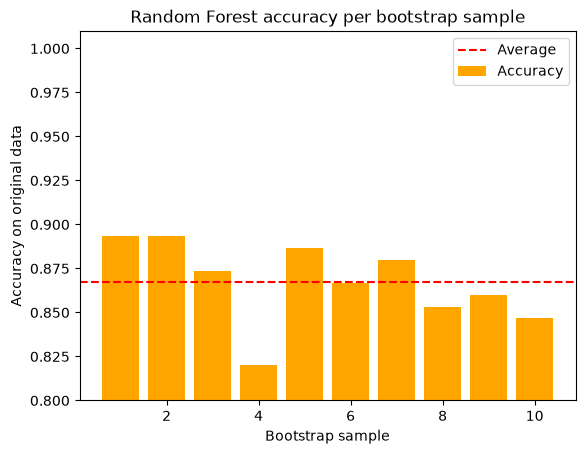

In [9]:
plt.bar(range(1, n_boot + 1), scores, color="orange", label="Accuracy")
plt.axhline(np.mean(scores), color="red", linestyle="--", label="Average")
plt.title("Random Forest accuracy per bootstrap sample")
plt.xlabel("Bootstrap sample")
plt.ylabel("Accuracy on original data")
plt.ylim(0.8, 1.01)
plt.legend()
plt.show()

### Q23

Write a Python code to perform Leave-One-Out Cross-Validation (LOOCV) on a dataset using a Decision Tree Classifier. The dataset consists of features and labels as specified below.

Dataset Description:
- The dataset consists of 100 samples with 5 features.
- The target variable is binary (0 or 1).

Instructions:
- Import the necessary libraries.
- Load or create a synthetic dataset with the specified characteristics.
- Implement Leave-One-Out Cross-Validation (LOOCV).
- Train a Decision Tree Classifier on each training set and evaluate it on the left-out sample.

Print the accuracy for each iteration and the average accuracy across all iterations.

In [10]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import LeaveOneOut
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [11]:
# 100 samples, 5 features, binary target
X, y = make_classification(n_samples=100, n_features=5, n_informative=3, n_classes=2, random_state=42)
print("X shape:", X.shape)

X shape: (100, 5)


In [12]:
# LOOCV: 100 iterations, each time 1 sample is the test set
loo = LeaveOneOut()
scores = []
for i, (train_idx, test_idx) in enumerate(loo.split(X), start=1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))   # 1 = correct, 0 = wrong
    scores.append(acc)
    print(f"Iteration {i}: accuracy = {acc}")

print("Average accuracy:", np.mean(scores))

Iteration 1: accuracy = 1.0
Iteration 2: accuracy = 0.0
Iteration 3: accuracy = 1.0
Iteration 4: accuracy = 1.0
Iteration 5: accuracy = 1.0
Iteration 6: accuracy = 0.0
Iteration 7: accuracy = 1.0
Iteration 8: accuracy = 0.0
Iteration 9: accuracy = 1.0
Iteration 10: accuracy = 1.0
Iteration 11: accuracy = 1.0
Iteration 12: accuracy = 1.0
Iteration 13: accuracy = 0.0
Iteration 14: accuracy = 1.0
Iteration 15: accuracy = 0.0
Iteration 16: accuracy = 1.0
Iteration 17: accuracy = 1.0
Iteration 18: accuracy = 1.0
Iteration 19: accuracy = 1.0
Iteration 20: accuracy = 0.0
Iteration 21: accuracy = 1.0
Iteration 22: accuracy = 1.0
Iteration 23: accuracy = 1.0
Iteration 24: accuracy = 1.0
Iteration 25: accuracy = 0.0
Iteration 26: accuracy = 1.0
Iteration 27: accuracy = 1.0
Iteration 28: accuracy = 1.0
Iteration 29: accuracy = 1.0
Iteration 30: accuracy = 1.0
Iteration 31: accuracy = 1.0
Iteration 32: accuracy = 1.0
Iteration 33: accuracy = 1.0
Iteration 34: accuracy = 1.0
Iteration 35: accuracy 

Iteration 51: accuracy = 1.0
Iteration 52: accuracy = 0.0
Iteration 53: accuracy = 1.0
Iteration 54: accuracy = 1.0


Iteration 55: accuracy = 1.0
Iteration 56: accuracy = 1.0
Iteration 57: accuracy = 0.0
Iteration 58: accuracy = 1.0
Iteration 59: accuracy = 1.0
Iteration 60: accuracy = 1.0
Iteration 61: accuracy = 1.0
Iteration 62: accuracy = 0.0
Iteration 63: accuracy = 1.0
Iteration 64: accuracy = 1.0
Iteration 65: accuracy = 1.0
Iteration 66: accuracy = 0.0
Iteration 67: accuracy = 1.0
Iteration 68: accuracy = 1.0
Iteration 69: accuracy = 1.0
Iteration 70: accuracy = 1.0
Iteration 71: accuracy = 1.0
Iteration 72: accuracy = 1.0
Iteration 73: accuracy = 1.0
Iteration 74: accuracy = 1.0
Iteration 75: accuracy = 0.0
Iteration 76: accuracy = 1.0
Iteration 77: accuracy = 0.0
Iteration 78: accuracy = 1.0
Iteration 79: accuracy = 1.0
Iteration 80: accuracy = 1.0
Iteration 81: accuracy = 1.0
Iteration 82: accuracy = 1.0
Iteration 83: accuracy = 1.0
Iteration 84: accuracy = 1.0
Iteration 85: accuracy = 1.0
Iteration 86: accuracy = 1.0
Iteration 87: accuracy = 1.0
Iteration 88: accuracy = 1.0
Iteration 89: 

### Q24

Write a Python code to perform Leave-One-Out Cross-Validation (LOOCV) on a dataset using a Decision Tree Classifier. The dataset consists of features and labels as specified below.

Dataset Description:
- The dataset consists of 150 samples with 10 features.
- The target variable is categorical with three classes (0, 1, 2).
- Introduce some noise to the dataset to make the classification task more

Instructions:
- Import the necessary libraries.
- Load or create a synthetic dataset with the specified characteristics (make_classification), including noise.
- Implement Leave-One-Out Cross-Validation (LOOCV).
- Train a Decision Tree Classifier on each training set and evaluate it on the left-out sample.
- Calculate and print the accuracy for each iteration, as well as the confusion matrix for the final model.
- Calculate and print the average accuracy across all iterations.

Print confusion matrix and classificarion report.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import LeaveOneOut
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [14]:
# 150 samples, 10 features, 3 classes, flip_y=0.1 adds label noise (10% labels randomly changed)
X, y = make_classification(n_samples=150, n_features=10, n_informative=5, n_classes=3,
                           flip_y=0.1, random_state=42)
print("X shape:", X.shape, "| classes:", np.unique(y))

X shape: (150, 10) | classes: [0 1 2]


In [15]:
# LOOCV loop, keep every prediction to build the confusion matrix
loo = LeaveOneOut()
scores, y_true_all, y_pred_all = [], [], []
for i, (train_idx, test_idx) in enumerate(loo.split(X), start=1):
    model = DecisionTreeClassifier(random_state=42)
    model.fit(X[train_idx], y[train_idx])
    y_pred = model.predict(X[test_idx])
    acc = accuracy_score(y[test_idx], y_pred)
    scores.append(acc)
    y_true_all.append(y[test_idx][0])
    y_pred_all.append(y_pred[0])
    print(f"Iteration {i}: accuracy = {acc}")

print("\nAverage accuracy:", round(np.mean(scores), 4))

Iteration 1: accuracy = 0.0
Iteration 2: accuracy = 1.0
Iteration 3: accuracy = 1.0
Iteration 4: accuracy = 1.0
Iteration 5: accuracy = 0.0
Iteration 6: accuracy = 1.0
Iteration 7: accuracy = 1.0
Iteration 8: accuracy = 0.0
Iteration 9: accuracy = 1.0
Iteration 10: accuracy = 1.0
Iteration 11: accuracy = 1.0
Iteration 12: accuracy = 0.0
Iteration 13: accuracy = 0.0
Iteration 14: accuracy = 0.0
Iteration 15: accuracy = 1.0
Iteration 16: accuracy = 1.0
Iteration 17: accuracy = 1.0
Iteration 18: accuracy = 0.0
Iteration 19: accuracy = 1.0
Iteration 20: accuracy = 1.0
Iteration 21: accuracy = 1.0
Iteration 22: accuracy = 1.0
Iteration 23: accuracy = 1.0
Iteration 24: accuracy = 0.0
Iteration 25: accuracy = 0.0
Iteration 26: accuracy = 1.0
Iteration 27: accuracy = 0.0
Iteration 28: accuracy = 0.0
Iteration 29: accuracy = 1.0
Iteration 30: accuracy = 0.0
Iteration 31: accuracy = 1.0
Iteration 32: accuracy = 0.0
Iteration 33: accuracy = 1.0
Iteration 34: accuracy = 1.0
Iteration 35: accuracy 

Iteration 37: accuracy = 1.0
Iteration 38: accuracy = 0.0
Iteration 39: accuracy = 0.0
Iteration 40: accuracy = 0.0


Iteration 41: accuracy = 1.0
Iteration 42: accuracy = 1.0
Iteration 43: accuracy = 1.0
Iteration 44: accuracy = 0.0
Iteration 45: accuracy = 1.0
Iteration 46: accuracy = 0.0
Iteration 47: accuracy = 0.0
Iteration 48: accuracy = 0.0
Iteration 49: accuracy = 0.0
Iteration 50: accuracy = 0.0
Iteration 51: accuracy = 1.0
Iteration 52: accuracy = 0.0
Iteration 53: accuracy = 0.0
Iteration 54: accuracy = 0.0
Iteration 55: accuracy = 1.0
Iteration 56: accuracy = 0.0
Iteration 57: accuracy = 0.0
Iteration 58: accuracy = 1.0
Iteration 59: accuracy = 0.0
Iteration 60: accuracy = 0.0
Iteration 61: accuracy = 1.0
Iteration 62: accuracy = 0.0
Iteration 63: accuracy = 0.0
Iteration 64: accuracy = 1.0
Iteration 65: accuracy = 0.0
Iteration 66: accuracy = 0.0
Iteration 67: accuracy = 1.0
Iteration 68: accuracy = 1.0
Iteration 69: accuracy = 0.0
Iteration 70: accuracy = 1.0
Iteration 71: accuracy = 0.0
Iteration 72: accuracy = 1.0
Iteration 73: accuracy = 1.0
Iteration 74: accuracy = 1.0
Iteration 75: 

Iteration 78: accuracy = 0.0
Iteration 79: accuracy = 0.0
Iteration 80: accuracy = 1.0
Iteration 81: accuracy = 0.0


Iteration 82: accuracy = 1.0
Iteration 83: accuracy = 0.0
Iteration 84: accuracy = 0.0
Iteration 85: accuracy = 1.0
Iteration 86: accuracy = 1.0
Iteration 87: accuracy = 0.0
Iteration 88: accuracy = 1.0
Iteration 89: accuracy = 1.0
Iteration 90: accuracy = 0.0
Iteration 91: accuracy = 1.0
Iteration 92: accuracy = 1.0
Iteration 93: accuracy = 1.0
Iteration 94: accuracy = 0.0
Iteration 95: accuracy = 1.0
Iteration 96: accuracy = 1.0
Iteration 97: accuracy = 0.0
Iteration 98: accuracy = 0.0
Iteration 99: accuracy = 0.0
Iteration 100: accuracy = 1.0
Iteration 101: accuracy = 0.0
Iteration 102: accuracy = 0.0
Iteration 103: accuracy = 0.0
Iteration 104: accuracy = 1.0
Iteration 105: accuracy = 1.0
Iteration 106: accuracy = 0.0
Iteration 107: accuracy = 1.0
Iteration 108: accuracy = 0.0
Iteration 109: accuracy = 1.0
Iteration 110: accuracy = 1.0
Iteration 111: accuracy = 1.0
Iteration 112: accuracy = 1.0
Iteration 113: accuracy = 1.0
Iteration 114: accuracy = 1.0
Iteration 115: accuracy = 0.

Iteration 117: accuracy = 0.0
Iteration 118: accuracy = 0.0
Iteration 119: accuracy = 1.0
Iteration 120: accuracy = 0.0


Iteration 121: accuracy = 0.0
Iteration 122: accuracy = 1.0
Iteration 123: accuracy = 0.0
Iteration 124: accuracy = 0.0
Iteration 125: accuracy = 1.0
Iteration 126: accuracy = 1.0
Iteration 127: accuracy = 1.0
Iteration 128: accuracy = 1.0
Iteration 129: accuracy = 1.0
Iteration 130: accuracy = 1.0
Iteration 131: accuracy = 1.0
Iteration 132: accuracy = 1.0
Iteration 133: accuracy = 0.0
Iteration 134: accuracy = 1.0
Iteration 135: accuracy = 1.0
Iteration 136: accuracy = 1.0
Iteration 137: accuracy = 0.0
Iteration 138: accuracy = 0.0
Iteration 139: accuracy = 1.0
Iteration 140: accuracy = 1.0
Iteration 141: accuracy = 1.0
Iteration 142: accuracy = 1.0
Iteration 143: accuracy = 0.0
Iteration 144: accuracy = 1.0
Iteration 145: accuracy = 1.0
Iteration 146: accuracy = 1.0
Iteration 147: accuracy = 1.0
Iteration 148: accuracy = 1.0
Iteration 149: accuracy = 1.0
Iteration 150: accuracy = 1.0

Average accuracy: 0.5667


Confusion matrix:
[[33  5 11]
 [ 8 31 13]
 [18 10 21]]

Classification report:
              precision    recall  f1-score   support

           0       0.56      0.67      0.61        49
           1       0.67      0.60      0.63        52
           2       0.47      0.43      0.45        49

    accuracy                           0.57       150
   macro avg       0.57      0.57      0.56       150
weighted avg       0.57      0.57      0.56       150



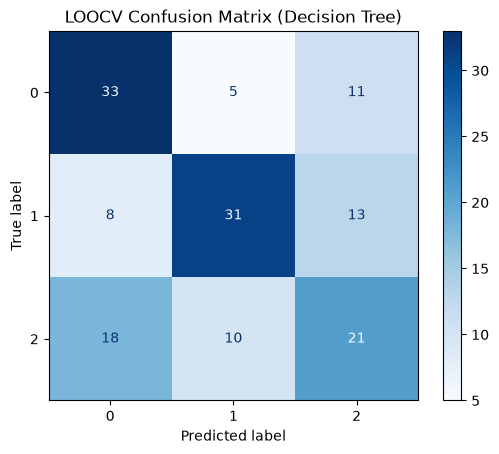

In [16]:
# Confusion matrix and classification report from all LOOCV predictions
print("Confusion matrix:")
print(confusion_matrix(y_true_all, y_pred_all))
print("\nClassification report:")
print(classification_report(y_true_all, y_pred_all))
ConfusionMatrixDisplay.from_predictions(y_true_all, y_pred_all, cmap="Blues")
plt.title("LOOCV Confusion Matrix (Decision Tree)")
plt.show()

### Q25

Write a Python code to perform Stratified K-Fold Cross-Validation on a dataset using a Random Forest Classifier. The dataset consists of features and labels as specified below.

Dataset Description:
- The dataset consists of 200 samples with 15 features.
- The target variable is categorical with four classes (0, 1, 2, 3).

Instructions:
- Import the necessary libraries.
- Load or create a synthetic dataset with the specified characteristics, ensuring class imbalance.
- Implement Stratified K-Fold Cross-Validation with 5 folds.
- Train a Random Forest Classifier on each training set and evaluate it on the validation set.
- Calculate and print the accuracy for each fold, as well as the average accuracy across all folds.

Generate and visualize the classification report for the final model, including precision, recall, and F1-score for each class.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [18]:
# 200 samples, 15 features, 4 imbalanced classes (50%, 25%, 15%, 10%)
X, y = make_classification(n_samples=200, n_features=15, n_informative=8, n_classes=4,
                           weights=[0.5, 0.25, 0.15, 0.1], random_state=42)
print("Class counts:", np.bincount(y))

Class counts: [101  50  29  20]


In [19]:
# Stratified 5-fold: each fold keeps the same class ratio
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []
for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))
    print(f"Fold {fold}: accuracy = {scores[-1]:.4f} | test class counts = {np.bincount(y_test)}")

print("Average accuracy:", round(np.mean(scores), 4))

Fold 1: accuracy = 0.6250 | test class counts = [20 10  6  4]


Fold 2: accuracy = 0.5500 | test class counts = [20 10  6  4]


Fold 3: accuracy = 0.6500 | test class counts = [20 10  6  4]


Fold 4: accuracy = 0.5750 | test class counts = [20 10  6  4]


Fold 5: accuracy = 0.6500 | test class counts = [21 10  5  4]
Average accuracy: 0.61


In [20]:
# Classification report for final model (last fold)
print(classification_report(y_test, y_pred, zero_division=0))
report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T
report = report.loc[["0", "1", "2", "3"], ["precision", "recall", "f1-score"]]
print(report.round(2))

              precision    recall  f1-score   support

           0       0.69      0.95      0.80        21
           1       0.67      0.60      0.63        10
           2       0.00      0.00      0.00         5
           3       0.00      0.00      0.00         4

    accuracy                           0.65        40
   macro avg       0.34      0.39      0.36        40
weighted avg       0.53      0.65      0.58        40

   precision  recall  f1-score
0       0.69    0.95      0.80
1       0.67    0.60      0.63
2       0.00    0.00      0.00
3       0.00    0.00      0.00


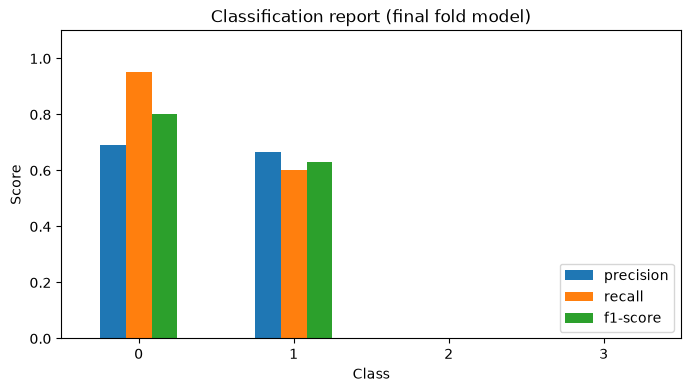

In [21]:
# Visualize the report
report.plot(kind="bar", figsize=(8, 4))
plt.title("Classification report (final fold model)")
plt.xlabel("Class")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

### Q26

Write a Python code to perform a Grid Search with Cross-Validation on the Iris dataset using a Support Vector Machine (SVM) classifier. The goal is to find the best hyperparameters for the SVM model.

Dataset Description:
- The Iris dataset consists of 150 samples with 4 features.
- The target variable is categorical with three classes (Setosa, Versicolor, Virginica).

Instructions:
- Import the necessary libraries.
- Load the Iris dataset from sklearn.datasets.
- Split the dataset into features and labels.
- Implement a Grid Search with 5-fold Cross-Validation to find the best hyperparameters for the SVM classifier. Consider the following hyperparameters: C: [0.1, 1, 10, 100] kernel: ['linear', 'rbf'] gamma: ['scale', 'auto']
- Print the best hyperparameters found by the Grid Search.
- Evaluate the best model on the entire dataset and print the accuracy.

Generate and visualize the confusion matrix for the best model.

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [23]:
# Load iris and split into features and labels
iris = load_iris()
X = iris.data
y = iris.target
print("X shape:", X.shape, "| classes:", iris.target_names.tolist())

X shape: (150, 4) | classes: ['setosa', 'versicolor', 'virginica']


In [24]:
# Grid search with 5-fold CV
params = {"C": [0.1, 1, 10, 100], "kernel": ["linear", "rbf"], "gamma": ["scale", "auto"]}
grid = GridSearchCV(SVC(), params, cv=5, scoring="accuracy")
grid.fit(X, y)
print("Best hyperparameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

Best hyperparameters: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV accuracy: 0.98


In [25]:
# All combinations ranked
res = pd.DataFrame(grid.cv_results_)[["param_C", "param_kernel", "param_gamma", "mean_test_score"]]
print(res.sort_values("mean_test_score", ascending=False).head(8))

    param_C param_kernel param_gamma  mean_test_score
6       1.0       linear        auto         0.980000
7       1.0          rbf        auto         0.980000
4       1.0       linear       scale         0.980000
9      10.0          rbf       scale         0.980000
11     10.0          rbf        auto         0.980000
8      10.0       linear       scale         0.973333
2       0.1       linear        auto         0.973333
0       0.1       linear       scale         0.973333


Accuracy on entire dataset: 0.9933333333333333


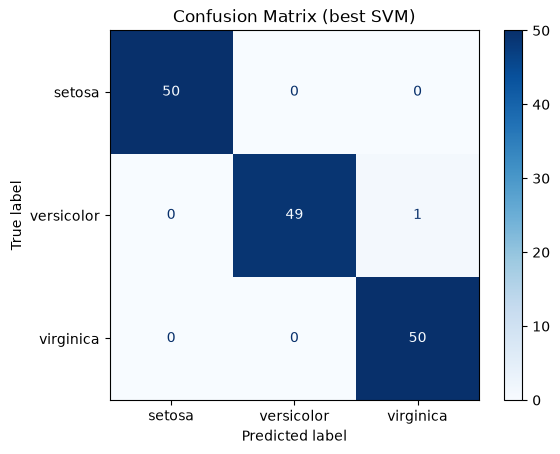

In [26]:
# Evaluate best model on entire dataset
model = grid.best_estimator_
y_pred = model.predict(X)
print("Accuracy on entire dataset:", accuracy_score(y, y_pred))

ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=iris.target_names, cmap="Blues")
plt.title("Confusion Matrix (best SVM)")
plt.show()